In [ ]:
import numpy as np
import sympy as sp
from sympy import latex
from IPython.display import display, Math
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.optimize import minimize

sp.init_printing()

## Задание 1. Проверка принципа Лагранжа и условий Куна–Таккера

Запишем ограничения в виде $g_i(x)\le 0$. Для задачи минимизации используем регулярную функцию Лагранжа
$$
L(x,\lambda)=f(x)+\sum_i \lambda_i g_i(x), \qquad \lambda_i\ge 0.
$$

KKT-система состоит из четырёх частей:

1. Допустимость: $g_i(x)\le 0$.
2. Неотрицательность множителей: $\lambda_i\ge 0$.
3. Дополняющая нежёсткость: $\lambda_i g_i(x)=0$.
4. Стационарность: $\nabla f(x)+\sum_i \lambda_i\nabla g_i(x)=0$.

Если ограничение записано как $h(x)\ge 0$, перед вычислениями заменим его на $g(x)=-h(x)\le 0$.

# 1.1

In [159]:
x1, x2 = sp.symbols("x1 x2", real=True)
y1, y2, y3 = sp.symbols("y1 y2 y3", nonnegative=True)

f = x2
f_grad = sp.Matrix([sp.diff(f, x) for x in (x1, x2)])
f_numeric = sp.lambdify((x1, x2), f, "numpy")
f_grad_numeric = sp.lambdify((x1, x2), f_grad, "numpy")

g1 = x1**2 + x2**2 - 1
g2 = -x1 + x2**2
g3 = -x1 - x2

g_numeric = [sp.lambdify((x1, x2), expr, "numpy") for expr in (g1, g2, g3)]
g_grad = [sp.Matrix([sp.diff(g, x) for x in (x1, x2)]) for g in (g1, g2, g3)]
g_grad_numeric = [sp.lambdify((x1, x2), grad, "numpy") for grad in g_grad]

# Регулярная функция Лагранжа: множитель при целевой функции равен 1
L = f + y1 * g1 + y2 * g2 + y3 * g3
grad_L = [sp.diff(L, x) for x in (x1, x2)]

display(Math("L = " + latex(L)))
display(Math("\\nabla L = " + latex(sp.Matrix(grad_L))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [ ]:
sqrt2 = sp.sqrt(2)
x_star = {x1: sp.sqrt(2) / 2, x2: -sp.sqrt(2) / 2}

# Система стационарности в известной точке
eqs = [sp.simplify(expr.subs(x_star)) for expr in grad_L]
print("Уравнения для множителей:")
display(Math("\\nabla L(x^*) = " + latex(sp.Matrix(eqs))))

# Решаем систему с учётом y_i >= 0
multipliers = sp.solve(eqs + [sp.Eq(y2, 0)], (y1, y2, y3), dict=True)

solution = multipliers[0]

display(
    Math(
        "\\mathbf{y} = " + latex(sp.Matrix([solution[y1], solution[y2], solution[y3]]))
    )
)

Уравнения для множителей:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [50]:
g_values = [sp.simplify(g.subs(x_star)) for g in (g1, g2, g3)]
print("Значения ограничений в x*:")
display(Math("\\mathbf{g}(x^*) = " + latex(sp.Matrix(g_values))))

y_star = {y1: sqrt2 / 4, y2: 0, y3: sp.Rational(1, 2)}

value_star = [sp.simplify(expr.subs(x_star).subs(y_star)) for expr in grad_L]
display(Math("\\nabla L(x^*, y^*) = " + latex(sp.Matrix(value_star))))

print("Множители неотрицательны:", all(y >= 0 for y in y_star.values()))
print(
    "Дополняющая нежёсткость:",
    [
        sp.simplify(y_star[y] * g.subs(x_star))
        for y, g in zip((y1, y2, y3), (g1, g2, g3))
    ],
)

Значения ограничений в x*:


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Множители неотрицательны: True
Дополняющая нежёсткость: [0, 0, 0]


# 1.2

In [52]:
slater_candidate = {x1: sp.Rational(1, 2), x2: 0}
slater_values = [sp.simplify(g.subs(slater_candidate)) for g in (g1, g2, g3)]

print("Кандидат:", slater_candidate)
print("Значения g_i:", slater_values)
print("Строго допустима:", all(v < 0 for v in slater_values))

Кандидат: {x1: 1/2, x2: 0}
Значения g_i: [-3/4, -1/2, -1/2]
Строго допустима: True


# 1.3

In [ ]:
np.random.seed(0)


def objective(x):
    return x[1]


num_starts = 3
dof = 2

# scipy SLSQP задаёт ограничения вида c(x) >= 0
constraints = [{"type": "ineq", "fun": f} for f in g_numeric]

starts = [np.random.rand(dof) for _ in range(num_starts)]

results = [
    minimize(
        objective,
        x0,
        method="SLSQP",
        constraints=constraints,
        options={"ftol": 1e-12, "maxiter": 1000},
    )
    for x0 in starts
]

In [ ]:
for i, res in enumerate(results, 1):
    x_latex = latex(sp.Matrix([sp.nsimplify(v) for v in res.x]))
    x_star_num = np.array([float(v) for v in x_star.values()])
    verdict_x = (
        "Совпадает с аналитическим решением"
        if np.allclose(res.x, x_star_num, atol=1e-3)
        else "Не совпадает с аналитическим решением"
    )

    f_latex = latex(sp.nsimplify(res.fun))

    constraint_vals = np.array([g(*res.x) for g in g_numeric])
    constraint_vals_latex = latex(sp.Matrix([round(v, 3) for v in constraint_vals]))

    y_latex = latex(sp.Matrix([sp.nsimplify(v) for v in res.multipliers]))
    y_star_num = np.array([float(v) for v in y_star.values()])
    verdict = (
        "Совпадает с аналитическим решением"
        if np.allclose(res.multipliers, y_star_num, atol=1e-3)
        else "Не совпадает с аналитическим решением"
    )

    display(
        Math(
            rf"\quad x^{{({i})}} \approx {x_latex} (\text{{{verdict_x}}})"
            rf"\quad f(x^{{({i})}}) \approx {f_latex}"
        )
    )
    display(
        Math(
            rf"\text{{Сходимость метода}} = {res.success},"
            rf"\quad \mathbf{{g}}(x^{{({i})}}) = {constraint_vals_latex}"
        )
    )
    display(
        Math(
            rf"\text{{Множители Лагранжа: }} \mathbf{{y}} \approx {y_latex}"
            rf"(\text{{{verdict}}})"
        )
    )
    print("-" * 80)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

--------------------------------------------------------------------------------


<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (2 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

--------------------------------------------------------------------------------


In [165]:
# Сетка для визуализации
limit = 2.1
N = 500
X2, X1 = np.mgrid[limit : -limit : N * 1j, limit : -limit : N * 1j]

# Допустимая область для ограничений
feasible = np.ones_like(X1, dtype=bool)
for g in g_numeric:
    feasible &= g(X1, X2) <= 0

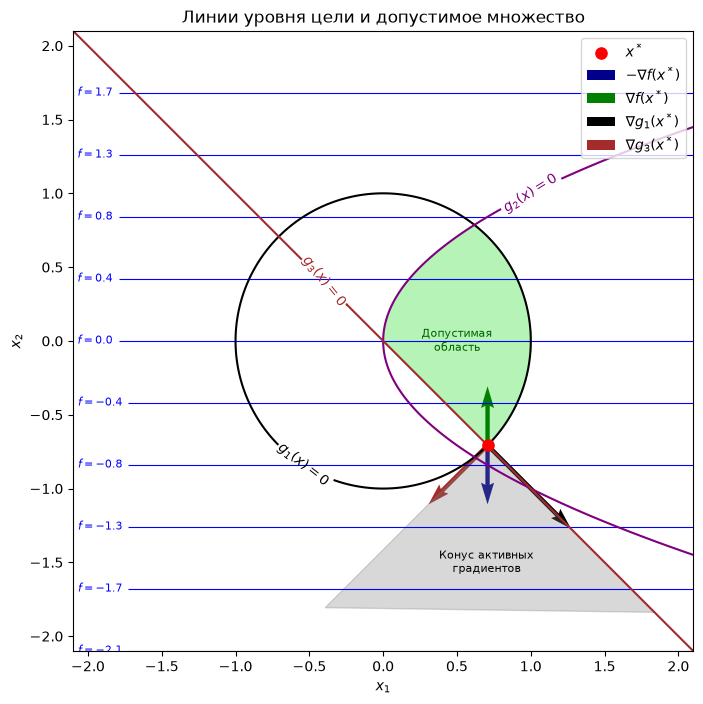

In [217]:
fig, ax = plt.subplots(figsize=(8, 10))

# Допустимая область
cs = ax.contourf(
    X1,
    X2,
    feasible.astype(float),
    levels=[0.5, 1.5],
    colors=["lightgreen"],
    alpha=0.65,
)

ax.text(
    0.5,
    0.0,
    "Допустимая\nобласть",
    fontsize=8,
    ha="center",
    va="center",
    color="darkgreen",
)

# Линии уровня целевой функции f(x) = x₂
contours = ax.contour(
    X1,
    X2,
    X2,
    levels=np.linspace(-limit, limit, 11),
    colors="blue",
    linewidths=0.8,
    linestyles="solid",
)

ax.clabel(contours, inline=True, fontsize=8, fmt=r"$f=%1.1f$")

# Границы ограничений
colors = ["black", "purple", "brown"]
manual_positions = {1: [(-0.5, -0.8)], 2: [(1, 1)], 3: [(-0.4, 0.4)]}

for i, (g, color) in enumerate(zip(g_numeric, colors), 1):
    Z = g(X1, X2)

    cs = ax.contour(X1, X2, Z, levels=[0], colors=[color])

    ax.clabel(
        cs,
        inline=True,
        fontsize=10,
        fmt={0: rf"$g_{i}(x)=0$"},
        manual=manual_positions.get(i),
    )

# Точка, указанная в условии
ax.scatter(*x_star_num, color="red", s=65, zorder=5, label="$x^*$")

# Градиенты цели и активных ограничений в x*
grads = {"f": f_grad_numeric, "g_1": g_grad_numeric[0], "g_3": g_grad_numeric[2]}

# -grad f в точке x*
neg_grad_f = -grads["f"](*x_star_num)
ax.quiver(
    *x_star_num,
    *neg_grad_f,
    angles="xy",
    scale_units="xy",
    scale=2.5,
    color="darkblue",
    width=0.007,
    label="$-\\nabla f(x^*)$",
)

colors_grad = ["green", "black", "brown"]

for (expr, grad), color in zip(grads.items(), colors_grad):
    grad_num = np.array(grad(*x_star_num), dtype=float).flatten()
    ax.quiver(
        *x_star_num,
        *grad_num,
        angles="xy",
        scale_units="xy",
        scale=2.5,
        color=color,
        width=0.007,
        label=rf"$\nabla {expr}(x^*)$",
    )

# Конус, натянутый на активные градиенты в x*
v1 = np.array(grads["g_1"](*x_star_num), dtype=float).flatten()
v3 = np.array(grads["g_3"](*x_star_num), dtype=float).flatten()
cone_vertices = [x_star_num, x_star_num + v1 * 0.8, x_star_num + v3 * 1.1]
cone = Polygon(cone_vertices, closed=True, color="gray", alpha=0.3)
ax.add_patch(cone)

ax.text(
    0.7,
    -1.5,
    "Конус активных\nградиентов",
    fontsize=8,
    ha="center",
    va="center",
    color="black",
)

ax.set(
    xlabel="$x_1$",
    ylabel="$x_2$",
    xlim=(-limit, limit),
    ylim=(-limit, limit),
    title="Линии уровня цели и допустимое множество",
)
ax.set_aspect("equal")
ax.legend(loc="upper right")
plt.show()

## Задание 2. Проверка условий регулярности

<IPython.core.display.Math object>

<IPython.core.display.Math object>

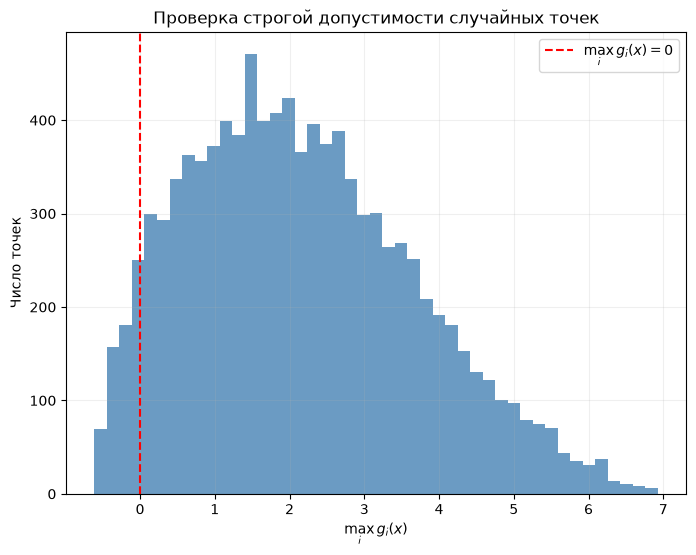

In [ ]:
np.random.seed(42)

samples = np.random.uniform(-2, 2, size=(10_000, 2))
g_samples = np.column_stack([g(*samples.T) for g in g_numeric])

strictly_feasible = np.all(g_samples < 0, axis=1)
max_g = np.max(g_samples, axis=1)

display(
    Math(
        rf"N = {len(samples)},\quad "
        rf"N_{{\mathrm{{strict}}}} = {strictly_feasible.sum()}"
    )
)

if strictly_feasible.any():
    slater_point = samples[strictly_feasible][0]
    display(
        Math(
            "\\bar{x} = "
            + latex(sp.Matrix([sp.Float(v, 5) for v in slater_point]))
            + ", \\quad  \\mathbf{g}(\\bar{x}) = "
            + latex(
                sp.Matrix([sp.Float(v, 5) for v in g_samples[strictly_feasible][0]])
            )
        )
    )

fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(max_g, bins=45, color="steelblue", alpha=0.8)
ax.axvline(0, color="red", linestyle="--", label="$\\max_i g_i(x)=0$")
ax.set(
    xlabel="$\\max_i g_i(x)$",
    ylabel="Число точек",
    title="Проверка строгой допустимости случайных точек",
)
ax.grid(alpha=0.2)
ax.legend()
plt.show()

## 2.2. Нерегулярная задача 1

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

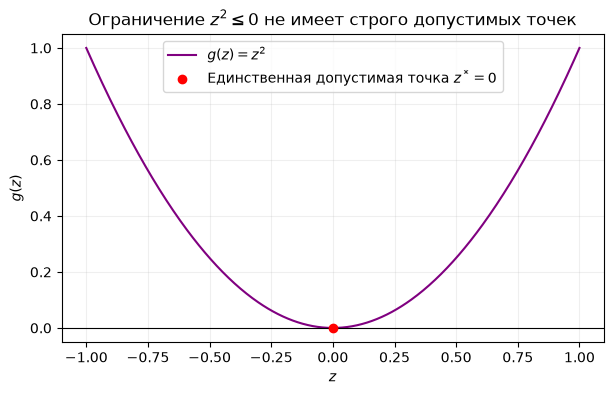

In [ ]:
z = sp.symbols("z", real=True)
mu = sp.symbols("mu", nonnegative=True)

f_bad = z
g_bad = z**2
L_bad = f_bad + mu * g_bad

display(Math(r"\min f(z)=z,\quad g(z)=z^2\leq 0,\quad z\in\mathbb{R}"))
display(
    Math(
        r"L(z,\mu)="
        + latex(L_bad)
        + r",\qquad \frac{\partial L}{\partial z}="
        + latex(sp.diff(L_bad, z))
    )
)

# Единственная допустимая точка и проверка условия Слейтера
z_star = 0
display(
    Math(
        rf"z^*={z_star},\quad g(z^*)={g_bad.subs(z, z_star)},"
        r"\quad \nexists\,\bar z:\ g(\bar z)<0"
    )
)

# KKT при фиксированном множителе при цели y_0 = 1
stationarity_regular = sp.diff(L_bad, z).subs(z, z_star)
display(
    Math(
        r"\left.\frac{\partial L}{\partial z}\right|_{z=0}"
        r"=1+\mu\cdot 0=1\ne0"
    )
)

# Формальный выход при y_0 = 0
y0, y = sp.symbols("y_0 y", nonnegative=True)
stationarity_general = y0 * sp.diff(f_bad, z) + y * sp.diff(g_bad, z)

display(
    Math(r"y_0=0:\quad " + latex(stationarity_general.subs({y0: 0, z: z_star})) + r"=0")
)
display(Math(r"\text{Подходит, например, } y_0=0,\ y=1."))

fig, ax = plt.subplots(figsize=(7, 4))
z_grid = np.linspace(-1, 1, 500)
ax.plot(z_grid, z_grid**2, color="purple", label=r"$g(z)=z^2$")
ax.axhline(0, color="black", linewidth=0.8)
ax.scatter(
    [0], [0], color="red", zorder=3, label=r"Единственная допустимая точка $z^*=0$"
)
ax.set(
    xlabel="$z$",
    ylabel="$g(z)$",
    title=r"Ограничение $z^2\leq 0$ не имеет строго допустимых точек",
)
ax.grid(alpha=0.2)
ax.legend()
plt.show()

## 2.3. Нерегулярная задача 2

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

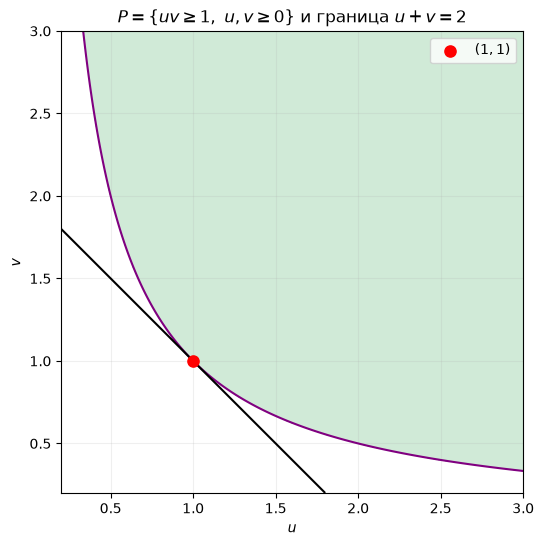

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [228]:
u, v = sp.symbols("u v", real=True)
mu = sp.symbols("mu", nonnegative=True)

f_irregular = u
g_irregular = u + v - 2
u_star = v_star = 1

display(
    Math(
        "f(u,v)=u,\\quad g(u,v)=u+v-2\\leq 0,\\quad P=\\{(u,v):uv \\geq1,\\ u\\geq0,\\ v\\geq0\\}"
    )
)
display(Math("(u^*,v^*)=(1,1),\\quad u^*v^*=1,\\quad g(u^*,v^*)=0"))

# На P всегда u+v >= 2, а g <= 0 требует u+v <= 2.
# Равенство возможно только в точке (1, 1).
display(
    Math(
        "uv\\geq1,\\ u,v\\geq0\\Rightarrow u+v\\geq2;"
        "\\quad g(u,v)\\leq0\\Rightarrow u+v\\leq2"
    )
)
display(Math("\\text{Следовательно, допустимое множество }=\\{(1,1)\\}."))

# Визуализация P, границы ограничения и единственной допустимой точки
U, V = np.meshgrid(np.linspace(0.2, 3, 500), np.linspace(0.2, 3, 500))
P_mask = U * V >= 1

fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(
    U,
    V,
    P_mask.astype(float),
    levels=[0.5, 1.5],
    colors=["#b8e0c2"],
    alpha=0.65,
)
ax.contour(U, V, U * V, levels=[1], colors=["purple"])
ax.contour(U, V, U + V, levels=[2], colors=["black"])
ax.scatter([1], [1], color="red", s=65, zorder=5, label="$(1,1)$")
ax.set(
    xlim=(0.2, 3),
    ylim=(0.2, 3),
    xlabel="$u$",
    ylabel="$v$",
    title="$P=\\{uv\\geq1,\\ u,v\\geq0\\}$ и граница $u+v=2$",
)
ax.set_aspect("equal")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

display(
    Math(
        "P\\text{ не полиэдр: его граница }uv=1"
        "\\text{ — гипербола, а не объединение отрезков прямых}"
    )
)
display(Math("(1,1)\\in\\partial P,\\quad (1,1)\\notin\\operatorname{ri}P"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

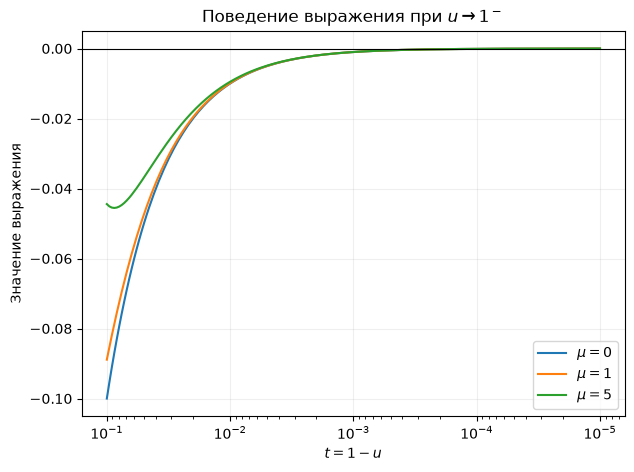

In [241]:
t = sp.symbols("t", positive=True)
expr = (1 + mu) * (u - 1) + mu * (1/u - 1)

expr_on_hyperbola = sp.factor(expr.subs(u, 1 - t))
expr_limit = sp.limit(expr_on_hyperbola, t, 0, dir="+")
display(Math(
    r"\left[(1+\mu)(u-1)+\mu\left(\frac1u-1\right)\right]_{u=1-t}"
    r"="
    + latex(sp.factor(expr_on_hyperbola))
))
display(Math(
    r"\lim_{t\to0^+}(\cdots)=" + latex(expr_limit)
))

# Численная иллюстрация для нескольких значений множителя
t_values = np.logspace(-5, -1, 200)

fig, ax = plt.subplots(figsize=(7, 5))
for mu_value in [0, 1, 5]:
    expr_values = np.array([
        float(expr_on_hyperbola.subs({mu: mu_value, t: tv}))
        for tv in t_values
    ])
    ax.plot(t_values, expr_values, label=rf"$\mu={mu_value}$")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.invert_xaxis()
ax.set(
    xlabel=r"$t=1-u$",
    ylabel="Значение выражения",
    title=r"Поведение выражения при $u\to1^-$",
)
ax.grid(alpha=0.2)
ax.legend()
plt.show()

$$
(1+y)(x_1-1)+y(x_2-1),
\qquad x_2=\frac1{x_1},\quad x_1<1,
$$

$ x_1=1-t$, где $t\to0^+ $

$$
(1+y)(-t)+y\left(\frac{1}{1-t}-1\right)
=-t\left(1-\frac{yt}{1-t}\right)
\longrightarrow 0^-.
$$